# NYC 311 weekly demand: exploration
Raw monthly aggregates (Socrata) -> weekly panel (week x community district x target). Run from the repo root.

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")
import duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt
from nyc311.config import load_categories, load_settings
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
s = load_settings(); cats = load_categories()
panel = pd.read_parquet(s.processed_dir / "weekly_panel.parquet")
panel["week_start"] = pd.to_datetime(panel["week_start"])
print(panel.shape, panel.week_start.min().date(), "->", panel.week_start.max().date())
TARGETS = [t for t in cats.targets if t != "total"]

(151230, 6) 2020-01-06 -> 2026-10-19


## Top 60 complaint types, 2025

In [2]:
glob = str(s.raw_dir / "daily_2025-*.parquet")
top = duckdb.sql(f"SELECT complaint_type, sum(n) AS n FROM read_parquet('{glob}') GROUP BY 1 ORDER BY 2 DESC LIMIT 60").df()
top["category"] = [cats.exact.get(t.strip().lower()) or next((c for p, c in cats.prefixes if t.strip().lower().startswith(p)), "(unmapped)") for t in top.complaint_type]
top.to_string()

'                    complaint_type         n           category\n0                  Illegal Parking  577257.0    illegal_parking\n1              Noise - Residential  463349.0              noise\n2                   HEAT/HOT WATER  315946.0     heat_hot_water\n3          Noise - Street/Sidewalk  173049.0              noise\n4                 Blocked Driveway  172723.0    illegal_parking\n5             UNSANITARY CONDITION  117749.0         (unmapped)\n6                     Water System   77432.0         (unmapped)\n7                 Street Condition   70330.0  street_conditions\n8                         PLUMBING   69548.0         (unmapped)\n9                Abandoned Vehicle   67903.0    illegal_parking\n10              Noise - Commercial   63958.0              noise\n11                 Dirty Condition   61047.0         sanitation\n12                   PAINT/PLASTER   59242.0         (unmapped)\n13                           Noise   55721.0              noise\n14                      

## Category check and unmapped share
Each target should average at least 1,000 requests per week citywide.

In [3]:
wk = panel.groupby(["week_start", "target"])["count"].sum().unstack()
avg = wk.mean().round(0); display(avg.to_frame("mean weekly citywide")); assert (avg[TARGETS] >= 1000).all()
allglob = str(s.raw_dir / "daily_*.parquet")
total = duckdb.sql(f"SELECT sum(n) FROM read_parquet('{allglob}')").fetchall()[0][0]
mapped = panel[panel.target != "total"]["count"].sum()
print(f"Mapped to 5 targets: {mapped/total:.1%} of all requests; unmapped (other complaint types): {1-mapped/total:.1%}")

,mean weekly citywide
target,
heat_hot_water,4715.0
illegal_parking,12577.0
noise,14613.0
sanitation,3544.0
street_conditions,3474.0
total,63388.0


Mapped to 5 targets: 60.2% of all requests; unmapped (other complaint types): 39.8%


## Citywide weekly total (COVID period shaded)

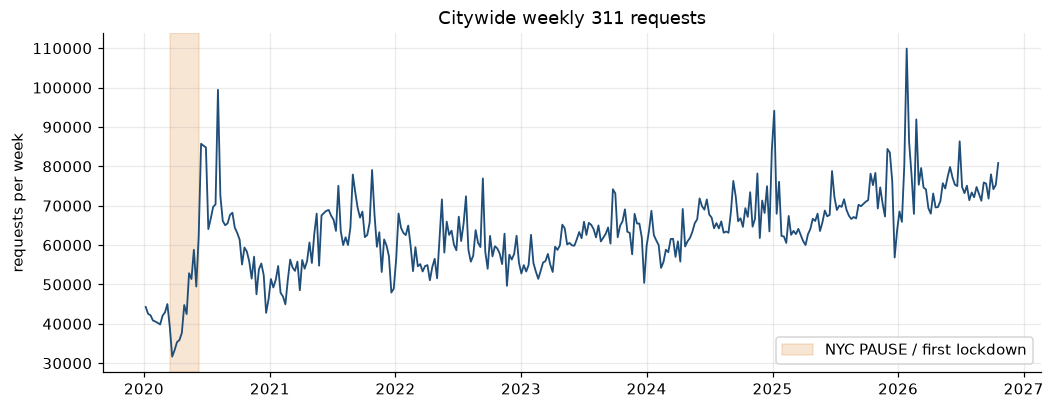

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(wk.index, wk["total"], color="#1f4e79", lw=1.2)
ax.axvspan(pd.Timestamp("2020-03-16"), pd.Timestamp("2020-06-08"), color="#d9822b", alpha=.2, label="NYC PAUSE / first lockdown")
ax.set(title="Citywide weekly 311 requests", ylabel="requests per week"); ax.legend(); plt.show()

## Seasonality by target (mean by ISO week of year, 2022 onward)

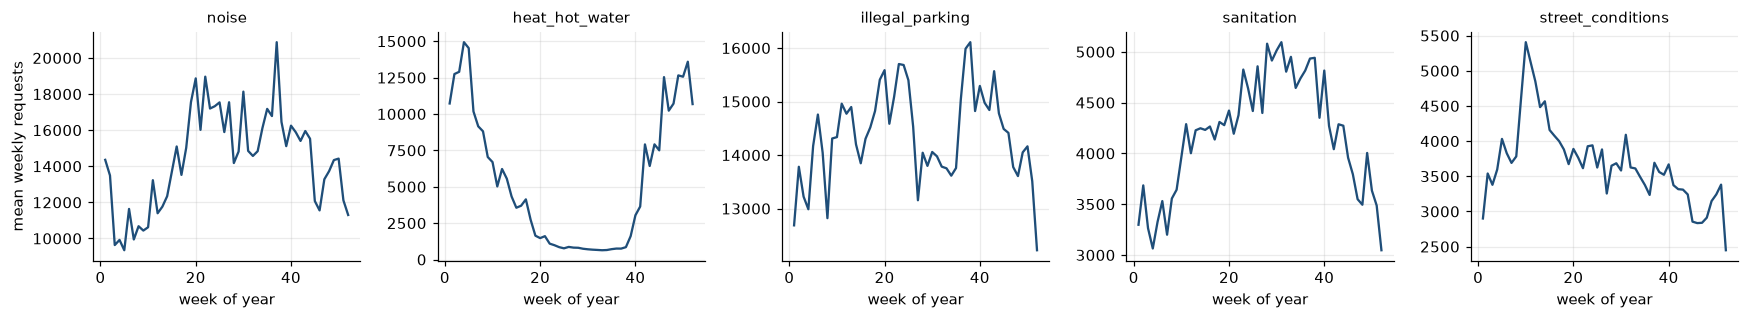

In [5]:
w = wk[wk.index >= "2022-01-01"].copy(); w["woy"] = w.index.isocalendar().week.values
seas = w.groupby("woy")[TARGETS].mean()
fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharex=True)
for ax, t in zip(axes, TARGETS):
    ax.plot(seas.index, seas[t], color="#1f4e79"); ax.set_title(t, fontsize=10); ax.set_xlabel("week of year")
axes[0].set_ylabel("mean weekly requests"); plt.tight_layout(); plt.show()

## Six districts, small multiples (total)

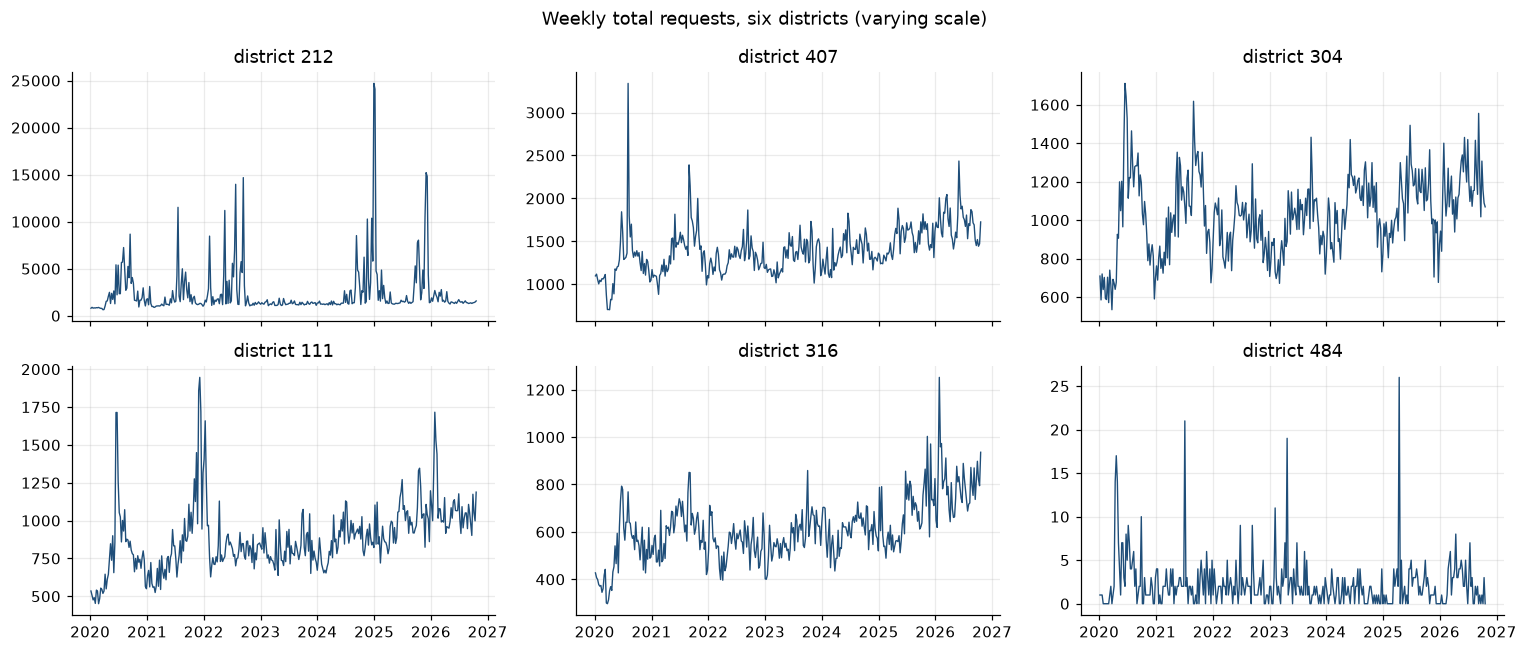

In [6]:
ids = panel[panel.target == "total"].groupby("borocd")["count"].sum().sort_values(ascending=False)
six = [ids.index[0], ids.index[10], ids.index[25], ids.index[40], ids.index[55], ids.index[-1]]
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for ax, b in zip(axes.flat, six):
    d = panel[(panel.borocd == b) & (panel.target == "total")]
    ax.plot(d.week_start, d["count"], lw=.9, color="#1f4e79"); ax.set_title(f"district {b}")
plt.suptitle("Weekly total requests, six districts (varying scale)"); plt.tight_layout(); plt.show()

## Weekly totals per borough

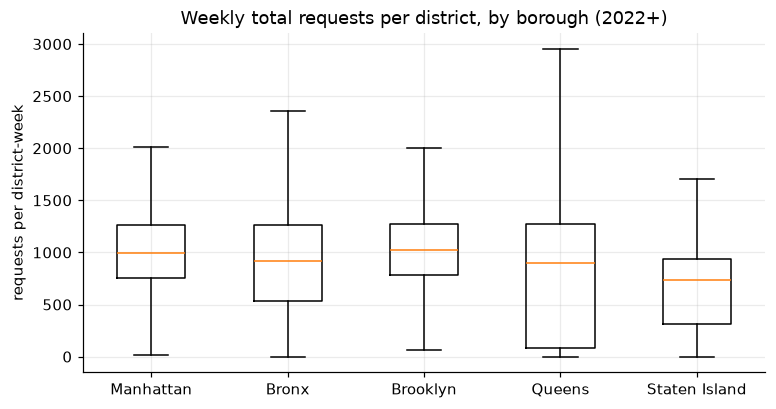

In [7]:
t = panel[panel.target == "total"].copy(); t["borough"] = t.borocd.astype(str).str[0].map({"1":"Manhattan","2":"Bronx","3":"Brooklyn","4":"Queens","5":"Staten Island"}).fillna("Other")
t = t[t.week_start >= "2022-01-01"]
order = ["Manhattan","Bronx","Brooklyn","Queens","Staten Island"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([t[t.borough == b]["count"] for b in order], tick_labels=order, showfliers=False)
ax.set(title="Weekly total requests per district, by borough (2022+)", ylabel="requests per district-week"); plt.show()